<a href="https://colab.research.google.com/github/wonhoyeo-oss/CV2026/blob/main/SLOC01_MNIST_MLP_keras_ipynb%EC%9D%98_%EC%82%AC%EB%B3%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
import numpy as np
tf.random.set_seed(1)

In [2]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Activation

In [3]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train = x_train.astype('float32')
x_test = x_test.astype('float32')

gray_scale = 255
x_train /= gray_scale
x_test /= gray_scale

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [4]:
model = Sequential([
    Flatten(input_shape=(28, 28)),    # reshape 28 row * 28 column data to 28*28=784 rows
    Dense(256, activation='sigmoid'), # dense layer 1
    Dense(128, activation='sigmoid'), # dense layer 2
    Dense(10, activation='softmax'),  # dense layer 3
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [5]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.layers
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
model.fit(x_train, y_train, epochs=10, batch_size=2000, validation_split = 0.2)

Epoch 1/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 66ms/step - accuracy: 0.4162 - loss: 2.0883 - val_accuracy: 0.6915 - val_loss: 1.7385
Epoch 2/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 63ms/step - accuracy: 0.7304 - loss: 1.3979 - val_accuracy: 0.8055 - val_loss: 1.0357
Epoch 3/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 63ms/step - accuracy: 0.8176 - loss: 0.8636 - val_accuracy: 0.8608 - val_loss: 0.6689
Epoch 4/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 60ms/step - accuracy: 0.8627 - loss: 0.6035 - val_accuracy: 0.8869 - val_loss: 0.4934
Epoch 5/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 71ms/step - accuracy: 0.8872 - loss: 0.4702 - val_accuracy: 0.9013 - val_loss: 0.4016
Epoch 6/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 102ms/step - accuracy: 0.8985 - loss: 0.3963 - val_accuracy: 0.9081 - val_loss: 0.3492
Epoch 7/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - accuracy: 0.9059 - loss: 0.3512 - val_accuracy: 0.9136 - val_loss: 0.3157
Epoch 8/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - accuracy: 0.9122 - loss: 0.3205 - val_accuracy: 0.9189 - 

In [7]:
results = model.evaluate(x_test, y_test, verbose = 2)

313/313 - 1s - 5ms/step - accuracy: 0.9246 - loss: 0.2660


In [8]:
print(results)

[0.2659778594970703, 0.9246000051498413]


In [9]:
from matplotlib import pyplot as plt

In [10]:
i=2013
image = x_test[i]*255
print(image.shape)

(28, 28)


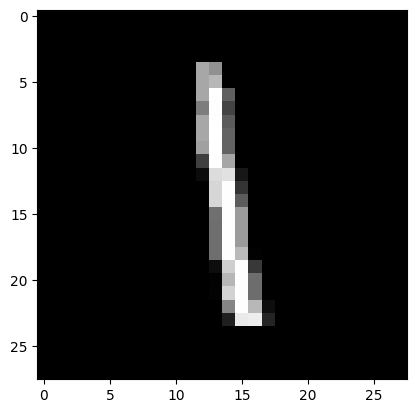

In [11]:
image = np.array(image, dtype='uint8')
plt.imshow(image, cmap='gray')

In [12]:
y_test[i]

np.uint8(1)

In [13]:
pred = model.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [14]:
print(pred[i])

[6.6471701e-05 9.7183603e-01 2.9937297e-03 3.9401813e-03 3.2187466e-04
 6.3114432e-03 3.1424339e-03 3.4689573e-03 6.5538120e-03 1.3648750e-03]


In [15]:
np.set_printoptions(edgeitems=10, linewidth=130, formatter=dict(float=lambda x: "%4.2f" % x))
print(pred)

[[0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.99 0.00 0.00]
 [0.01 0.01 0.95 0.02 0.00 0.01 0.01 0.00 0.01 0.00]
 [0.00 0.98 0.01 0.00 0.00 0.00 0.00 0.01 0.00 0.00]
 [0.99 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 0.00 0.00 0.94 0.00 0.00 0.01 0.00 0.04]
 [0.00 0.98 0.00 0.00 0.00 0.00 0.00 0.01 0.00 0.00]
 [0.00 0.00 0.00 0.00 0.95 0.01 0.00 0.00 0.02 0.02]
 [0.00 0.00 0.00 0.00 0.05 0.01 0.00 0.00 0.02 0.91]
 [0.02 0.00 0.01 0.00 0.14 0.03 0.80 0.00 0.01 0.00]
 [0.00 0.00 0.00 0.00 0.03 0.00 0.00 0.04 0.00 0.92]
 ...
 [0.00 0.00 0.01 0.01 0.00 0.00 0.00 0.97 0.00 0.01]
 [0.00 0.00 0.01 0.06 0.00 0.01 0.00 0.00 0.92 0.00]
 [0.00 0.00 0.00 0.00 0.18 0.00 0.00 0.01 0.00 0.80]
 [0.98 0.00 0.00 0.00 0.00 0.02 0.00 0.00 0.01 0.00]
 [0.00 0.98 0.01 0.00 0.00 0.00 0.00 0.00 0.01 0.00]
 [0.00 0.00 0.98 0.01 0.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 0.00 0.99 0.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 0.00 0.00 0.93 0.00 0.00 0.00 0.01 0.06]
 [0.00 0.00 0.00 0.00 0.00 0.90 0.00 0.00

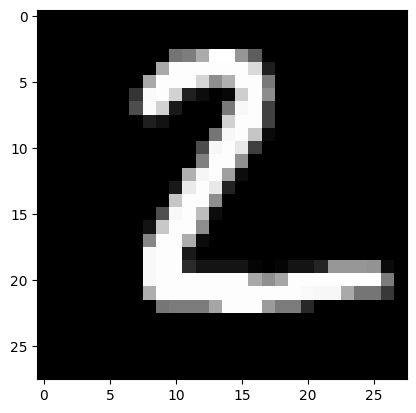

In [16]:
image = np.array(x_test[1]*255, dtype='uint8')
plt.imshow(image, cmap='gray')